# Imagenes satelitales con Mapbox y ajuste fino de Inception v3 (regresion de precio)
Antes de correr
1. Entorno de ejecucion > Cambiar tipo de entorno > GPU T4.
2. En Secretos (icono de llave) crea MAPBOX_TOKEN con tu token y activa el acceso desde el cuaderno.
3. Sube a la carpeta Taller3_imagenes de tu Drive train_planas.csv, test_planas.csv y folds_bloques.csv.
4. Para una prueba rapida deja folds_a_correr = [1] y hacer_final = False en la seccion (1).

In [2]:
# Archivo: 04_imagenes_colab.ipynb
# Proyecto: Problem Set 3, prediccion de precios Chapinero
# Descripcion: descarga imagenes satelitales de Mapbox (zoom 17) por celda de unos 50 m,
#              ajusta los ultimos bloques de Inception v3 para predecir el precio por m2
#              (una red por fold de validacion) y extrae 256 rasgos por celda
# Input: train_planas.csv, test_planas.csv, folds_bloques.csv
# Output: features_s{semilla}_fold{k}.csv y features_final.csv (celda_id, f1 a f256)

# (1) Librerias y parametros -------------------------------------------------
import os
import time
import numpy as np
import pandas as pd
import requests
from concurrent.futures import ThreadPoolExecutor
from google.colab import drive, userdata
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import InceptionV3

drive.mount("/content/drive")

zoom = 17                    # zoom de Mapbox, cubre unos 357 m
tamano_descarga = 600        # pixeles pedidos a Mapbox
tamano_red = 299             # tamano de entrada de Inception v3
n_rasgos = 32               # numero de rasgos que se extraen por celda
paso_grados = 0.00045        # tamano de celda, unos 50 m en Bogota
hilos = 8                    # descargas en paralelo
semilla_folds = 1            # semilla de bloques, columna fold_s1 de folds_bloques.csv
folds_a_correr = [1, 2, 3, 4, 5]
hacer_final = True           # red con todo el train, para las predicciones de test
epocas_fase1 = 3             # solo la cabeza nueva, base congelada
epocas_fase2 = 6             # ultimos bloques de Inception descongelados
tam_lote = 32

token = userdata.get("MAPBOX_TOKEN")
dir_base = "/content/drive/MyDrive/Taller3_imagenes"
dir_img = os.path.join(dir_base, "img")
os.makedirs(dir_img, exist_ok=True)
tf.keras.utils.set_random_seed(2025)

Mounted at /content/drive


In [3]:
# (2) Ubicaciones desde train y test -----------------------------------------
def fun_celda(lon, lat):
    cx = np.floor(lon / paso_grados).astype(int).astype(str)
    cy = np.floor(lat / paso_grados).astype(int).astype(str)
    return cx + "_" + cy

train = pd.read_csv(os.path.join(dir_base, "train_planas.csv"),
                    usecols=["property_id", "price", "surface_covered", "lon", "lat"])
test = pd.read_csv(os.path.join(dir_base, "test_planas.csv"), usecols=["lon", "lat"])

celdas = pd.concat([train[["lon", "lat"]], test])
celdas["celda_id"] = fun_celda(celdas["lon"], celdas["lat"])
celdas = celdas.groupby("celda_id", as_index=False).agg(lon=("lon", "mean"), lat=("lat", "mean"))

print(len(celdas), "celdas")

13748 celdas


In [4]:
# (3) Funcion de descarga ----------------------------------------------------
def fun_ruta_img(id_celda):
    return os.path.join(dir_img, f"{id_celda}_z{zoom}.jpg")

def fun_descargar(fila):
    id_celda, lon, lat = fila
    ruta = fun_ruta_img(id_celda)
    if os.path.exists(ruta):          # si ya existe no se vuelve a pedir
        return True
    url = (f"https://api.mapbox.com/styles/v1/mapbox/satellite-v9/static/"
           f"{lon},{lat},{zoom},0/{tamano_descarga}x{tamano_descarga}"
           f"?access_token={token}&attribution=false&logo=false")
    for intento in range(4):
        try:
            r = requests.get(url, timeout=30)
            if r.status_code == 200:
                with open(ruta, "wb") as f:
                    f.write(r.content)
                return True
            if r.status_code == 429:   # demasiadas peticiones, esperar
                time.sleep(10)
        except requests.RequestException:
            time.sleep(3)
    return False

In [5]:
# (4) Descarga en paralelo ---------------------------------------------------
pedidos = list(zip(celdas["celda_id"], celdas["lon"], celdas["lat"]))

with ThreadPoolExecutor(max_workers=hilos) as pool:
    resultados = list(pool.map(fun_descargar, pedidos))

fallidos = [p for p, ok in zip(pedidos, resultados) if not ok]
print("descargadas:", sum(resultados), "fallidas:", len(fallidos))   # si hay fallidas, repetir esta seccion

descargadas: 13748 fallidas: 0


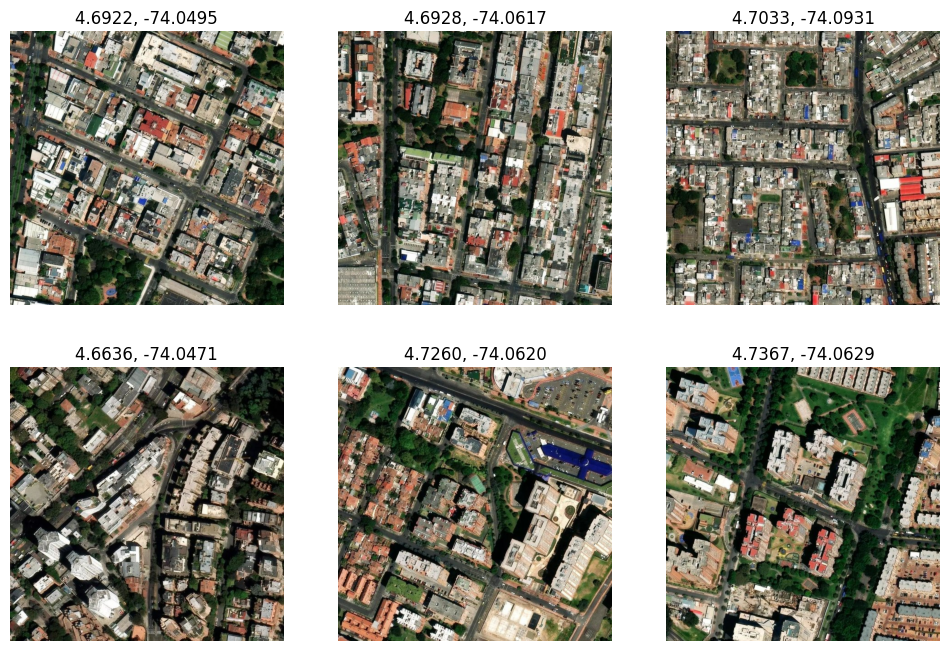

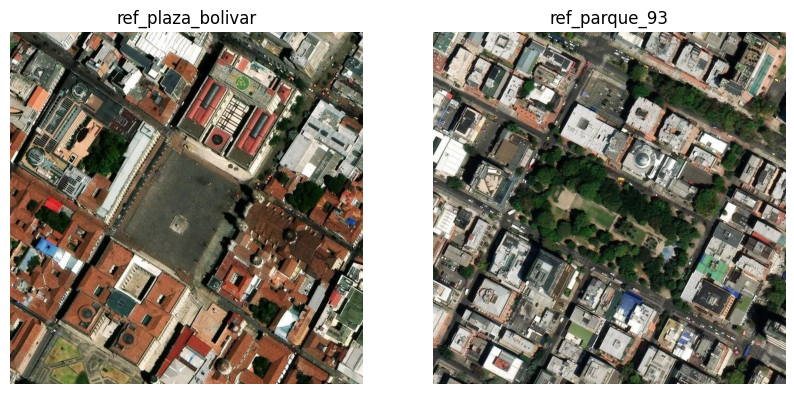

In [6]:
# (4b) Verificacion visual de las imagenes ------------------------------------
import matplotlib.pyplot as plt

# seis celdas al azar con su coordenada
muestra = celdas.sample(n=6, random_state=1).reset_index(drop=True)
fig, ejes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (_, fila) in zip(ejes.flat, muestra.iterrows()):
    ax.imshow(Image.open(fun_ruta_img(fila["celda_id"])))
    ax.set_title(f"{fila['lat']:.4f}, {fila['lon']:.4f}")
    ax.axis("off")
plt.show()

# dos lugares conocidos como referencia (lon, lat)
referencias = {"ref_plaza_bolivar": (-74.0760, 4.5981), "ref_parque_93": (-74.0483, 4.6769)}
fig, ejes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (nombre, (lo, la)) in zip(ejes, referencias.items()):
    fun_descargar((nombre, lo, la))
    ax.imshow(Image.open(fun_ruta_img(nombre)))
    ax.set_title(nombre)
    ax.axis("off")
plt.show()

In [7]:
# (5) Cache de la parte congelada de Inception v3 ----------------------------
# Los bloques hasta mixed8 no se entrenan, asi que cada imagen pasa por ellos una
# sola vez y el resultado (mapas de 8 x 8 x 1280) se guarda. Los entrenamientos
# solo recorren mixed9, mixed10 y la cabeza nueva. La primera vez tarda, las
# siguientes lee el archivo de Drive
assert len(fallidos) == 0, "faltan imagenes, repetir la seccion (4)"

posicion = {c: i for i, c in enumerate(celdas["celda_id"])}
archivo_cache = os.path.join(dir_base, "cache_mixed8.npy")
lote_cache = 32                  # imagenes por tanda al llenar el cache

def fun_cargar(id_celda):
    with Image.open(fun_ruta_img(id_celda)) as im:
        return np.asarray(im.convert("RGB").resize((tamano_red, tamano_red)), dtype=np.uint8)

if os.path.exists(archivo_cache):
    cache = np.load(archivo_cache)
else:
    base0 = InceptionV3(weights="imagenet", include_top=False, pooling=None,
                        input_shape=(tamano_red, tamano_red, 3))
    fija = Model(base0.input, base0.get_layer("mixed8").output)
    cache = np.zeros((len(celdas), 8, 8, 1280), dtype=np.float16)
    ids = celdas["celda_id"].values
    with ThreadPoolExecutor(max_workers=hilos) as pool:
        for i in range(0, len(ids), lote_cache):
            arr = np.stack(list(pool.map(fun_cargar, ids[i:i + lote_cache]))).astype("float32")
            cache[i:i + lote_cache] = fija(arr / 127.5 - 1, training=False).numpy()   # escala de Inception v3
    np.save(archivo_cache, cache)

print(cache.shape, round(cache.nbytes / 1e9, 1), "GB")

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(13748, 8, 8, 1280) 2.3 GB


In [8]:
# (6) Folds y etiquetas por celda --------------------------------------------
# etiqueta de cada fila: log del precio por m2. Cada celda recibe la mediana de las
# filas de entrenamiento que caen en ella
folds = pd.read_csv(os.path.join(dir_base, "folds_bloques.csv"))
col_fold = f"fold_s{semilla_folds}"

filas = train.merge(folds[["property_id", col_fold]], on="property_id", how="left")
filas = filas.rename(columns={col_fold: "fold"})
assert len(filas) == len(train) and filas["fold"].notna().all(), "los folds no cubren todo el train"
filas["celda_id"] = fun_celda(filas["lon"], filas["lat"])
valida = (filas["price"] > 0) & (filas["surface_covered"] > 0)
filas["etiqueta"] = np.where(valida, np.log(filas["price"] / filas["surface_covered"]), np.nan)

def fun_celdas_entrenamiento(fold):
    if fold is None:
        ent = filas
    else:
        ent = filas[filas["fold"] != fold]
        celdas_val = set(filas.loc[filas["fold"] == fold, "celda_id"])   # celdas con filas de validacion
        ent = ent[~ent["celda_id"].isin(celdas_val)]
    ent = ent.dropna(subset=["etiqueta"])
    bajo, alto = ent["etiqueta"].quantile([0.01, 0.99])
    ent = ent.assign(etiqueta=ent["etiqueta"].clip(bajo, alto))         # recorta valores extremos
    return ent.groupby("celda_id", as_index=False).agg(etiqueta=("etiqueta", "median"))

In [9]:
# (7) Red, entrenamiento y extraccion de rasgos ------------------------------
# la red es mixed9 y mixed10 de Inception v3 (ImageNet), un promedio global, una
# capa densa de n_rasgos con ReLU (los rasgos) y una salida lineal que predice el
# log del precio por m2. Recibe los mapas guardados en cache
def fun_modelo():
    base = InceptionV3(weights="imagenet", include_top=False, pooling=None,
                       input_shape=(tamano_red, tamano_red, 3))
    parte = Model(base.get_layer("mixed8").output, base.output)   # de mixed8 al final
    entrada = layers.Input((8, 8, 1280))
    x = parte(entrada)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(n_rasgos, activation="relu", name="rasgos")(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(1, name="precio")(x)
    return Model(entrada, salida), parte

def fun_descongelar(parte):
    # se descongelan mixed9 y mixed10, las capas BatchNorm siguen congeladas
    parte.trainable = True
    for capa in parte.layers:
        capa.trainable = not isinstance(capa, layers.BatchNormalization)

clase_base = getattr(tf.keras.utils, "PyDataset", tf.keras.utils.Sequence)

class Lotes(clase_base):
    def __init__(self, idx, y, mezclar):
        super().__init__()
        self.idx = np.array(idx)
        self.y = np.array(y, dtype="float32")
        self.mezclar = mezclar
        self.orden = np.arange(len(self.idx))
        if mezclar:
            np.random.shuffle(self.orden)
    def __len__(self):
        return int(np.ceil(len(self.idx) / tam_lote))
    def __getitem__(self, b):
        o = self.orden[b * tam_lote:(b + 1) * tam_lote]
        return cache[self.idx[o]].astype("float32"), self.y[o]
    def on_epoch_end(self):
        if self.mezclar:
            np.random.shuffle(self.orden)

def fun_entrenar(cel_ent, semilla):
    idx = cel_ent["celda_id"].map(posicion).values
    y = cel_ent["etiqueta"].values
    z = (y - y.mean()) / y.std()                       # etiqueta estandarizada
    perm = np.random.RandomState(semilla).permutation(len(idx))
    n_val = int(0.1 * len(idx))                        # 10% de celdas para vigilar sobreajuste
    iv, it = perm[:n_val], perm[n_val:]
    ent = Lotes(idx[it], z[it], True)
    val = Lotes(idx[iv], z[iv], False)

    modelo, parte = fun_modelo()
    parte.trainable = False                            # fase 1, solo la cabeza nueva
    modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    modelo.fit(ent, validation_data=val, epochs=epocas_fase1, verbose=0)

    fun_descongelar(parte)                             # fase 2, mixed9 y mixed10
    modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="mse", metrics=["mae"])
    parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    modelo.fit(ent, validation_data=val, epochs=epocas_fase2, callbacks=[parada], verbose=0)
    return modelo

def fun_rasgos(modelo):
    extractor = Model(modelo.input, modelo.get_layer("rasgos").output)
    salida = [extractor(cache[i:i + 256].astype("float32"), training=False).numpy()
              for i in range(0, len(cache), 256)]
    return np.vstack(salida)

# Validacion interna. Devuelve los rasgos de todas las celdas. Las celdas de
# entrenamiento reciben rasgos de una red que no vio su precio (se reparten en
# grupos y cada red deja un grupo por fuera). El resto (validacion, test y celdas
# sin etiqueta) recibe los rasgos de la red entrenada con todas las celdas de
# entrenamiento, que tampoco las vio
def fun_rasgos_fuera_de_muestra(cel_ent):
    modelo = fun_entrenar(cel_ent, 2025)
    rasgos = fun_rasgos(modelo)
    tf.keras.backend.clear_session()
    grupo = np.random.RandomState(2026).randint(0, grupos_internos, len(cel_ent))
    for j in range(grupos_internos):
        modelo_j = fun_entrenar(cel_ent[grupo != j], 2026 + j)
        rasgos_j = fun_rasgos(modelo_j)
        filas_j = cel_ent.loc[grupo == j, "celda_id"].map(posicion).values
        rasgos[filas_j] = rasgos_j[filas_j]
        tf.keras.backend.clear_session()
        print("  grupo interno", j + 1, "de", grupos_internos)
    return rasgos

def fun_guardar(rasgos, nombre):
    tabla = pd.DataFrame(rasgos, columns=[f"f{j + 1}" for j in range(n_rasgos)]).round(4)
    tabla.insert(0, "celda_id", celdas["celda_id"].values)
    tabla.to_csv(os.path.join(dir_base, nombre), index=False)

In [ ]:
# (8) Rasgos por fold --------------------------------------------------------
for k in folds_a_correr:
    nombre = f"features_s{semilla_folds}_fold{k}_n{n_rasgos}.csv"
    if os.path.exists(os.path.join(dir_base, nombre)):   # si ya existe se salta, permite retomar
        continue
    inicio = time.time()
    cel_ent = fun_celdas_entrenamiento(k)
    print("fold", k, "celdas de entrenamiento:", len(cel_ent))
    fun_guardar(fun_rasgos_fuera_de_muestra(cel_ent), nombre)
    print("fold", k, "minutos:", round((time.time() - inicio) / 60, 1))

fold 1 celdas de entrenamiento: 9549


In [ ]:
# (9) Rasgos finales con todo el train, para las predicciones de test --------
nombre_final = f"features_final_n{n_rasgos}.csv"
if hacer_final and not os.path.exists(os.path.join(dir_base, nombre_final)):
    cel_ent = fun_celdas_entrenamiento(None)
    print("final, celdas de entrenamiento:", len(cel_ent))
    fun_guardar(fun_rasgos_fuera_de_muestra(cel_ent), nombre_final)